In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Import the CPI dataset into a Pandas DataFrame

import pandas as pd

data_file = "data/CPI_Data.csv"

cpi_data = pd.read_csv(data_file, skiprows=8)

# Display the first five observations
print(cpi_data.head())

         date  STATIC_INFLATIONCALC
0  1914-01-01                   6.0
1  1914-02-01                   6.0
2  1914-03-01                   6.0
3  1914-04-01                   6.0
4  1914-05-01                   5.9


In [5]:
# Prepare the CPI data for analysis

# Convert the date column into datetime format
cpi_data["date"] = pd.to_datetime(cpi_data["date"])

# Convert CPI values into numeric format
cpi_data["STATIC_INFLATIONCALC"] = pd.to_numeric(
    cpi_data["STATIC_INFLATIONCALC"],
    errors="coerce"
)

# Remove any missing observations
cpi_data = cpi_data.dropna()

# Sort observations chronologically
cpi_data = cpi_data.sort_values("date")

# Display the first five cleaned observations
print(cpi_data.head())

        date  STATIC_INFLATIONCALC
0 1914-01-01                   6.0
1 1914-02-01                   6.0
2 1914-03-01                   6.0
3 1914-04-01                   6.0
4 1914-05-01                   5.9


In [6]:
# Calculate the annual percentage change in CPI

cpi_data["Annual Percentage Change"] = (
    cpi_data["STATIC_INFLATIONCALC"].pct_change(periods=12) * 100
)

# Display the first observations with the annual percentage change
print(cpi_data.head(20))

         date  STATIC_INFLATIONCALC  Annual Percentage Change
0  1914-01-01                   6.0                       NaN
1  1914-02-01                   6.0                       NaN
2  1914-03-01                   6.0                       NaN
3  1914-04-01                   6.0                       NaN
4  1914-05-01                   5.9                       NaN
5  1914-06-01                   6.0                       NaN
6  1914-07-01                   5.9                       NaN
7  1914-08-01                   6.0                       NaN
8  1914-09-01                   6.0                       NaN
9  1914-10-01                   6.1                       NaN
10 1914-11-01                   6.1                       NaN
11 1914-12-01                   6.1                       NaN
12 1915-01-01                   6.1                  1.666667
13 1915-02-01                   6.1                  1.666667
14 1915-03-01                   6.1                  1.666667
15 1915-

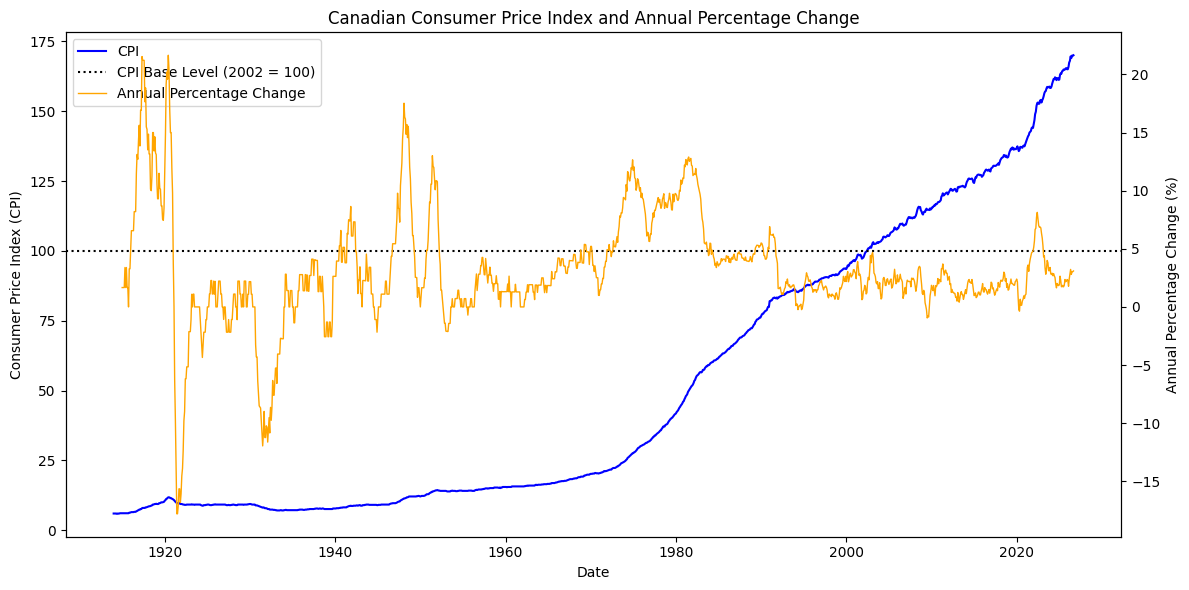

In [8]:
# Create the CPI time-series graph

fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot CPI on the left-hand axis
ax1.plot(
    cpi_data["date"],
    cpi_data["STATIC_INFLATIONCALC"],
    color="blue",
    label="CPI",
    linewidth=1.5
)

# Add dotted line representing the CPI base level
ax1.axhline(
    y=100,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label="CPI Base Level (2002 = 100)"
)

# Label the left-hand axis
ax1.set_xlabel("Date")
ax1.set_ylabel("Consumer Price Index (CPI)")

# Create a second axis for annual percentage change
ax2 = ax1.twinx()

ax2.plot(
    cpi_data["date"],
    cpi_data["Annual Percentage Change"],
    color="orange",
    label="Annual Percentage Change",
    linewidth=1
)

# Label the right-hand axis
ax2.set_ylabel("Annual Percentage Change (%)")

# Add graph title
ax1.set_title("Canadian Consumer Price Index and Annual Percentage Change")

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

# Adjust layout
fig.tight_layout()

# Save graph as a PNG file
plt.savefig("output/CPI_Graph.png", dpi=300, bbox_inches="tight")

# Display graph
plt.show()